# 🩺 Diabetes Prediction & Clinical Decision Support System
### Automated Screening: "Diabetes or Not" & Comprehensive Subtype Analysis

This notebook provides an end-to-end Machine Learning and Clinical Decision Support System that answers two vital clinical questions:
1. **Primary Screening**: **Does the patient have Diabetes or Not?**
   - 🟢 **NO DIABETES (Negative / Normal)**: Fasting blood glucose, insulin, and urinalysis are within healthy non-diabetic ranges.
   - 🟡 **PREDIABETES (Borderline / At Risk)**: Impaired fasting glucose or impaired glucose tolerance indicating heightened risk of progression.
   - 🔴 **DIABETES POSITIVE (Diabetes Detected / Yes)**: Clinical dysglycemia confirming diabetes.
2. **Subtype Diagnostic Classification**: If diabetes is present, determines the exact clinical subtype (Type 1, Type 2, Gestational, MODY, LADA, CFRD, Steroid-Induced, etc.) with confidence scores and differential diagnoses.
3. **Biomarker Reference Evaluation & Action Plan**: Evidence-based evaluation of Blood Glucose, Blood Pressure, BMI, Insulin, Cholesterol, and Urine metabolites against ADA, AHA, and WHO guidelines.


In [1]:
# 1. Setup & Library Imports
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Interactive Widgets & Display
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("✅ Setup complete. All libraries imported successfully.")


✅ Setup complete. All libraries imported successfully.


---
## 2. Data Ingestion & Dataset Overview
Loading `diabetes_dataset00.csv` containing 70,000 clinical records across 13 diabetes subtypes and 33 clinical, genetic, and demographic biomarkers.


In [2]:
# Load dataset
DATASET_PATH = 'diabetes_dataset00.csv'
df = pd.read_csv(DATASET_PATH)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().sum()} missing entries")
df.head(5)


Dataset Shape: 70,000 rows, 34 columns
Missing Values: 0 missing entries


,Target,Genetic Markers,Autoantibodies,Family History,Environmental Factors,Insulin Levels,Age,BMI,Physical Activity,Dietary Habits,...,Pulmonary Function,Cystic Fibrosis Diagnosis,Steroid Use History,Genetic Testing,Neurological Assessments,Liver Function Tests,Digestive Enzyme Levels,Urine Test,Birth Weight,Early Onset Symptoms
0,Steroid-Induced Diabetes,Positive,Negative,No,Present,40,44,38,High,Healthy,...,76,No,No,Positive,3,Normal,56,Ketones Present,2629,No
1,Neonatal Diabetes Mellitus (NDM),Positive,Negative,No,Present,13,1,17,High,Healthy,...,60,Yes,No,Negative,1,Normal,28,Glucose Present,1881,Yes
2,Prediabetic,Positive,Positive,Yes,Present,27,36,24,High,Unhealthy,...,80,Yes,No,Negative,1,Abnormal,55,Ketones Present,3622,Yes
3,Type 1 Diabetes,Negative,Positive,No,Present,8,7,16,Low,Unhealthy,...,89,Yes,No,Positive,2,Abnormal,60,Ketones Present,3542,No
4,Wolfram Syndrome,Negative,Negative,Yes,Present,17,10,17,High,Healthy,...,41,No,No,Positive,1,Normal,24,Protein Present,1770,No


In [3]:
# Numerical Biomarker Statistics
df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})


,count,mean,std,min,median,max
Insulin Levels,70000.0,21.607443,10.785852,5.0,19.0,49.0
Age,70000.0,32.020700,21.043173,0.0,31.0,79.0
BMI,70000.0,24.782943,6.014236,12.0,25.0,39.0
Blood Pressure,70000.0,111.339543,19.945000,60.0,113.0,149.0
Cholesterol Levels,70000.0,194.867200,44.532466,100.0,191.0,299.0
Waist Circumference,70000.0,35.051657,6.803461,20.0,34.0,54.0
Blood Glucose Levels,70000.0,160.701657,48.165547,80.0,152.0,299.0
Weight Gain During Pregnancy,70000.0,15.496414,9.633096,0.0,16.0,39.0
Pancreatic Health,70000.0,47.564243,19.984683,10.0,46.0,99.0
Pulmonary Function,70000.0,70.264671,11.965600,30.0,72.0,89.0


In [4]:
# Diagnostic Target Subtype Distribution
target_counts = df['Target'].value_counts()
print(f"Number of distinct diagnostic classes: {len(target_counts)}\n")
for target, count in target_counts.items():
    print(f"  • {target:45}: {count:5,} cases ({count/len(df)*100:.1f}%)")


Number of distinct diagnostic classes: 13

  • MODY                                         : 5,553 cases (7.9%)
  • Secondary Diabetes                           : 5,479 cases (7.8%)
  • Cystic Fibrosis-Related Diabetes (CFRD)      : 5,464 cases (7.8%)
  • Type 1 Diabetes                              : 5,446 cases (7.8%)
  • Neonatal Diabetes Mellitus (NDM)             : 5,408 cases (7.7%)
  • Wolcott-Rallison Syndrome                    : 5,400 cases (7.7%)
  • Type 2 Diabetes                              : 5,397 cases (7.7%)
  • Prediabetic                                  : 5,376 cases (7.7%)
  • Gestational Diabetes                         : 5,344 cases (7.6%)
  • Type 3c Diabetes (Pancreatogenic Diabetes)   : 5,320 cases (7.6%)
  • Wolfram Syndrome                             : 5,315 cases (7.6%)
  • Steroid-Induced Diabetes                     : 5,275 cases (7.5%)
  • LADA                                         : 5,223 cases (7.5%)


---
## 3. Exploratory Data Analysis & Biomarker Visualizations
Exploring clinical distributions and correlations among physiological measurements.


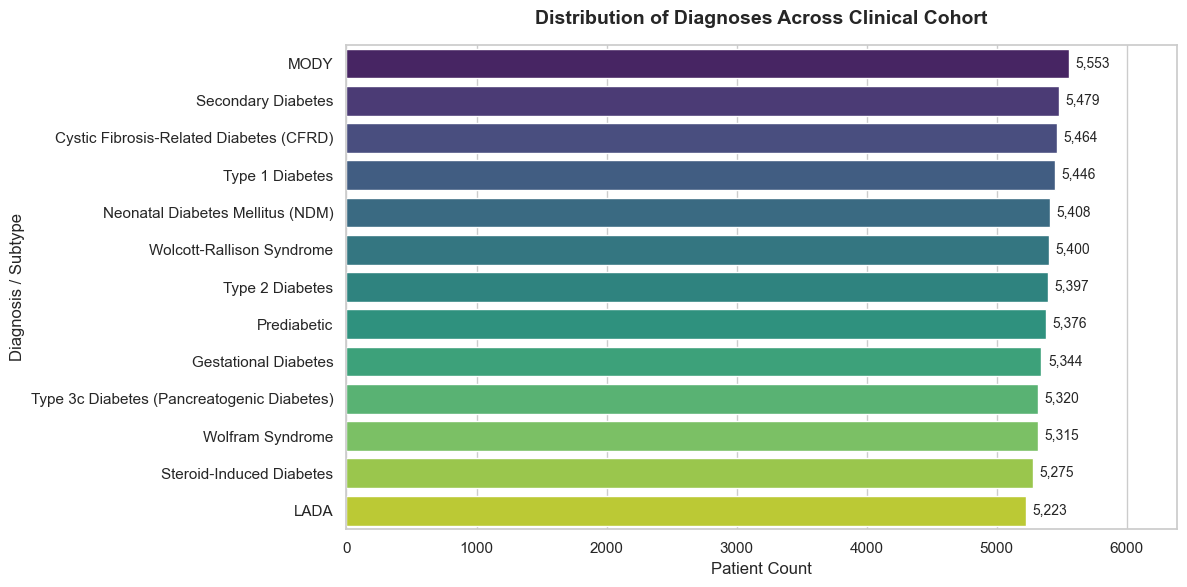

In [5]:
# 1. Target Subtype Distribution
plt.figure(figsize=(12, 6))
order = df['Target'].value_counts().index
ax = sns.countplot(data=df, y='Target', order=order, palette='viridis')
plt.title('Distribution of Diagnoses Across Clinical Cohort', fontsize=14, weight='bold', pad=15)
plt.xlabel('Patient Count', fontsize=12)
plt.ylabel('Diagnosis / Subtype', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}', (width + 50, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10)
plt.xlim(0, max(order.map(df['Target'].value_counts())) * 1.15)
plt.tight_layout()
plt.show()


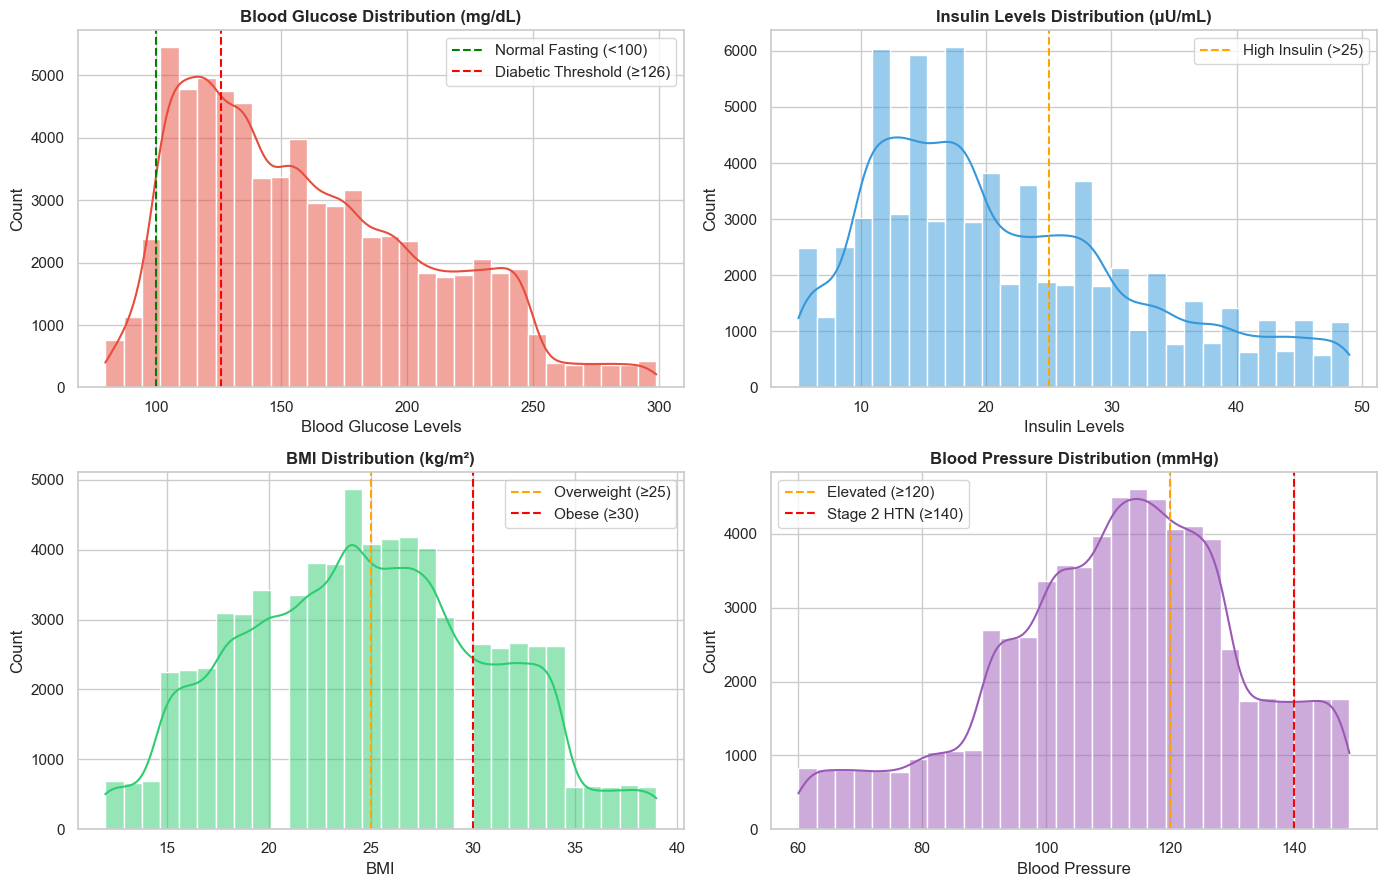

In [6]:
# 2. Key Biomarker Distributions: Blood Glucose, Insulin, BMI, Blood Pressure
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Glucose
sns.histplot(df['Blood Glucose Levels'], kde=True, ax=axes[0, 0], color='#e74c3c', bins=30)
axes[0, 0].axvline(100, color='green', linestyle='--', label='Normal Fasting (<100)')
axes[0, 0].axvline(126, color='red', linestyle='--', label='Diabetic Threshold (≥126)')
axes[0, 0].set_title('Blood Glucose Distribution (mg/dL)', weight='bold')
axes[0, 0].legend()

# Insulin
sns.histplot(df['Insulin Levels'], kde=True, ax=axes[0, 1], color='#3498db', bins=30)
axes[0, 1].axvline(25, color='orange', linestyle='--', label='High Insulin (>25)')
axes[0, 1].set_title('Insulin Levels Distribution (μU/mL)', weight='bold')
axes[0, 1].legend()

# BMI
sns.histplot(df['BMI'], kde=True, ax=axes[1, 0], color='#2ecc71', bins=30)
axes[1, 0].axvline(25, color='orange', linestyle='--', label='Overweight (≥25)')
axes[1, 0].axvline(30, color='red', linestyle='--', label='Obese (≥30)')
axes[1, 0].set_title('BMI Distribution (kg/m²)', weight='bold')
axes[1, 0].legend()

# Blood Pressure
sns.histplot(df['Blood Pressure'], kde=True, ax=axes[1, 1], color='#9b59b6', bins=30)
axes[1, 1].axvline(120, color='orange', linestyle='--', label='Elevated (≥120)')
axes[1, 1].axvline(140, color='red', linestyle='--', label='Stage 2 HTN (≥140)')
axes[1, 1].set_title('Blood Pressure Distribution (mmHg)', weight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


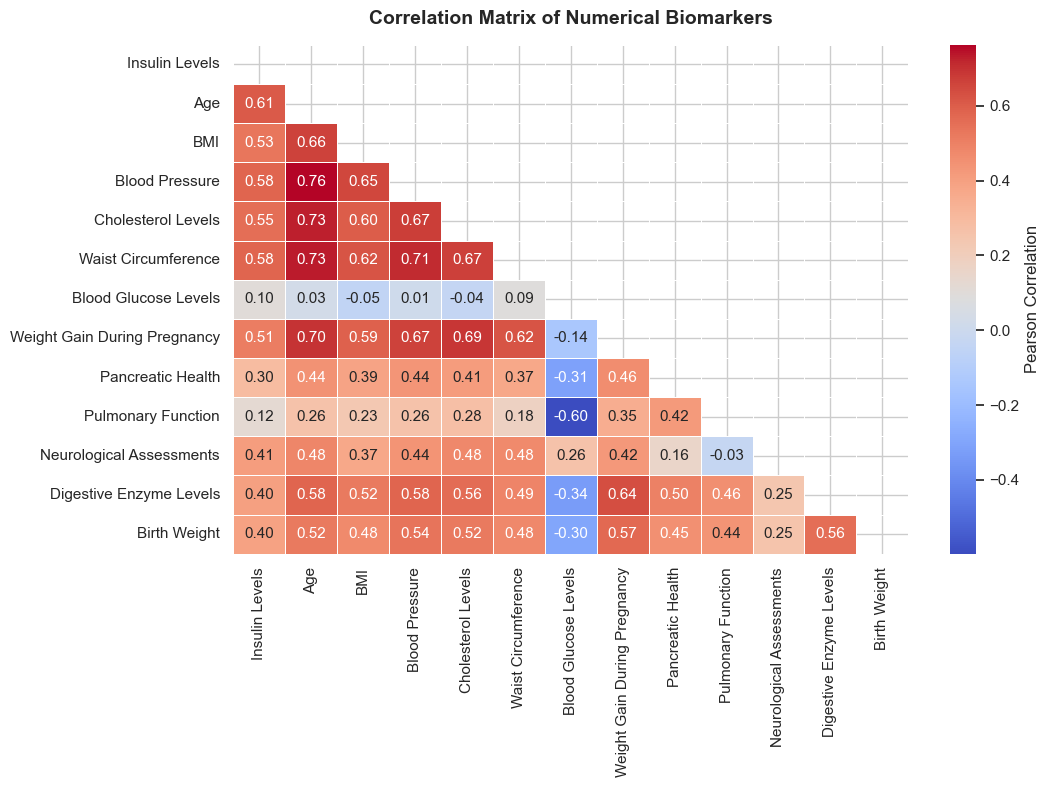

In [7]:
# 3. Correlation Heatmap of Numerical Clinical Biomarkers
num_features = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_features].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            cbar_kws={'label': 'Pearson Correlation'}, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Biomarkers', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()


---
## 4. Preprocessing & Encoding Pipeline
Preparing features and encoders for machine learning. We store category encoders and population baseline statistics (medians for numerical values, modes for categoricals) to ensure robust, production-ready inference.


In [8]:
# Feature and Target Separation
feature_cols = [c for c in df.columns if c != 'Target']
cat_cols = [c for c in feature_cols if df[c].dtype == 'object' or df[c].dtype.name.startswith('str')]
num_cols = [c for c in feature_cols if c not in cat_cols]

print(f"Total Features: {len(feature_cols)} ({len(num_cols)} numerical, {len(cat_cols)} categorical)")

# Fit and store encoders
encoders = {}
cat_mappings = {}
for col in cat_cols:
    le = LabelEncoder()
    le.fit(df[col].astype(str))
    encoders[col] = le
    cat_mappings[col] = {val.lower(): val for val in le.classes_}

# Target Encoder
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(df['Target'])

# Prepare encoded feature matrix X
X = df[feature_cols].copy()
for col in cat_cols:
    X[col] = encoders[col].transform(X[col].astype(str))

# Calculate population defaults (medians for numbers, modes for categories)
population_defaults = {}
for c in num_cols:
    population_defaults[c] = float(df[c].median())
for c in cat_cols:
    population_defaults[c] = str(df[c].mode()[0])

# Stratified Train/Test Split (80% Train, 20% Holdout Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Training Set: {X_train.shape[0]:,} samples")
print(f"Testing Set:  {X_test.shape[0]:,} samples")


Total Features: 33 (13 numerical, 20 categorical)


Training Set: 56,000 samples
Testing Set:  14,000 samples


---
## 5. Machine Learning Model Training & Feature Importance
Training an ensemble Random Forest Classifier with balanced class weights to diagnose diabetes subtypes accurately.


In [9]:
# Train Random Forest Model
model = RandomForestClassifier(
    n_estimators=120,
    max_depth=None,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest Classifier on 56,000 patient records...")
model.fit(X_train, y_train)
print("✅ Model training completed successfully.")


Training Random Forest Classifier on 56,000 patient records...


✅ Model training completed successfully.


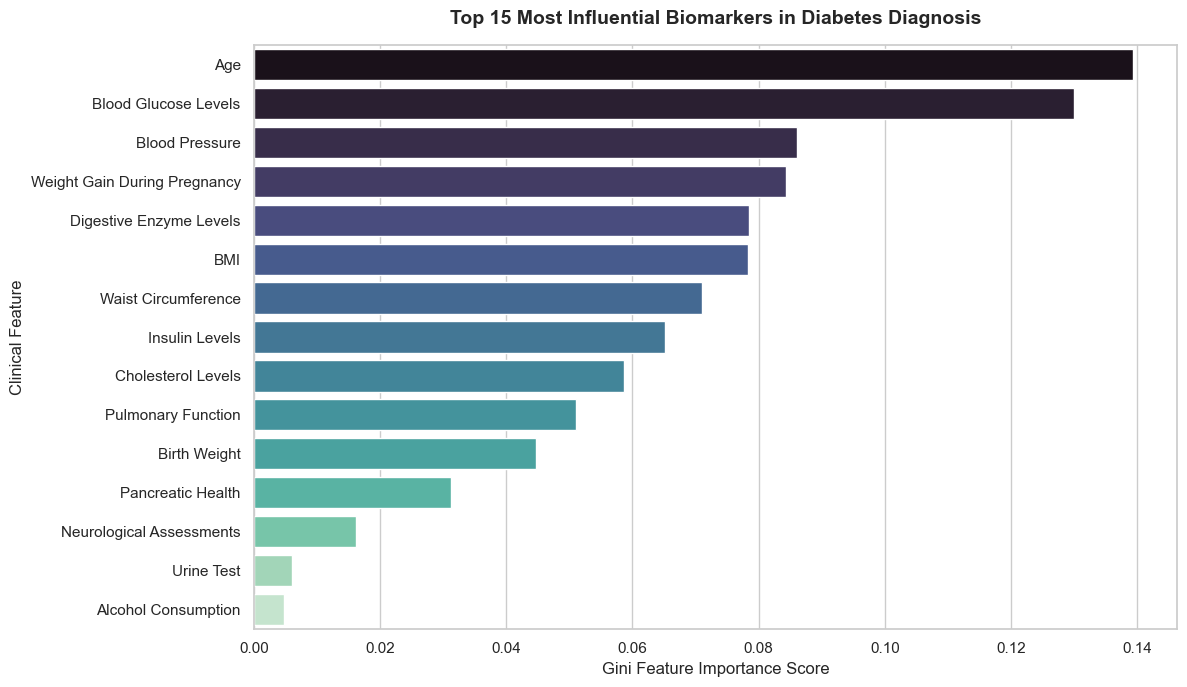

In [10]:
# Feature Importance Analysis
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='mako')
plt.title('Top 15 Most Influential Biomarkers in Diabetes Diagnosis', fontsize=14, weight='bold', pad=15)
plt.xlabel('Gini Feature Importance Score', fontsize=12)
plt.ylabel('Clinical Feature', fontsize=12)
plt.tight_layout()
plt.show()


---
## 6. Model Evaluation & Performance Metrics
Evaluating diagnostic precision, recall, and overall accuracy on the 14,000 independent test set patients.


In [11]:
# Test Set Evaluation
y_pred = model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

print("="*65)
print(f"  MODEL PERFORMANCE ON INDEPENDENT TEST SET (14,000 PATIENTS)")
print("="*65)
print(f"  • Overall Test Accuracy: {test_acc*100:.2f}%")
print(f"  • Macro F1-Score:       {macro_f1*100:.2f}%")
print(f"  • Weighted F1-Score:    {weighted_f1*100:.2f}%")
print("="*65)
print("\nDetailed Per-Subtype Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))


  MODEL PERFORMANCE ON INDEPENDENT TEST SET (14,000 PATIENTS)
  • Overall Test Accuracy: 90.26%
  • Macro F1-Score:       90.16%
  • Weighted F1-Score:    90.16%

Detailed Per-Subtype Classification Report:

                                            precision    recall  f1-score   support

   Cystic Fibrosis-Related Diabetes (CFRD)       0.99      0.91      0.95      1093
                      Gestational Diabetes       0.90      0.93      0.91      1069
                                      LADA       0.96      0.93      0.94      1044
                                      MODY       0.96      0.83      0.89      1111
          Neonatal Diabetes Mellitus (NDM)       1.00      1.00      1.00      1082
                               Prediabetic       0.96      1.00      0.98      1075
                        Secondary Diabetes       0.80      0.79      0.79      1096
                  Steroid-Induced Diabetes       0.83      0.82      0.82      1055
                           Type 1 D

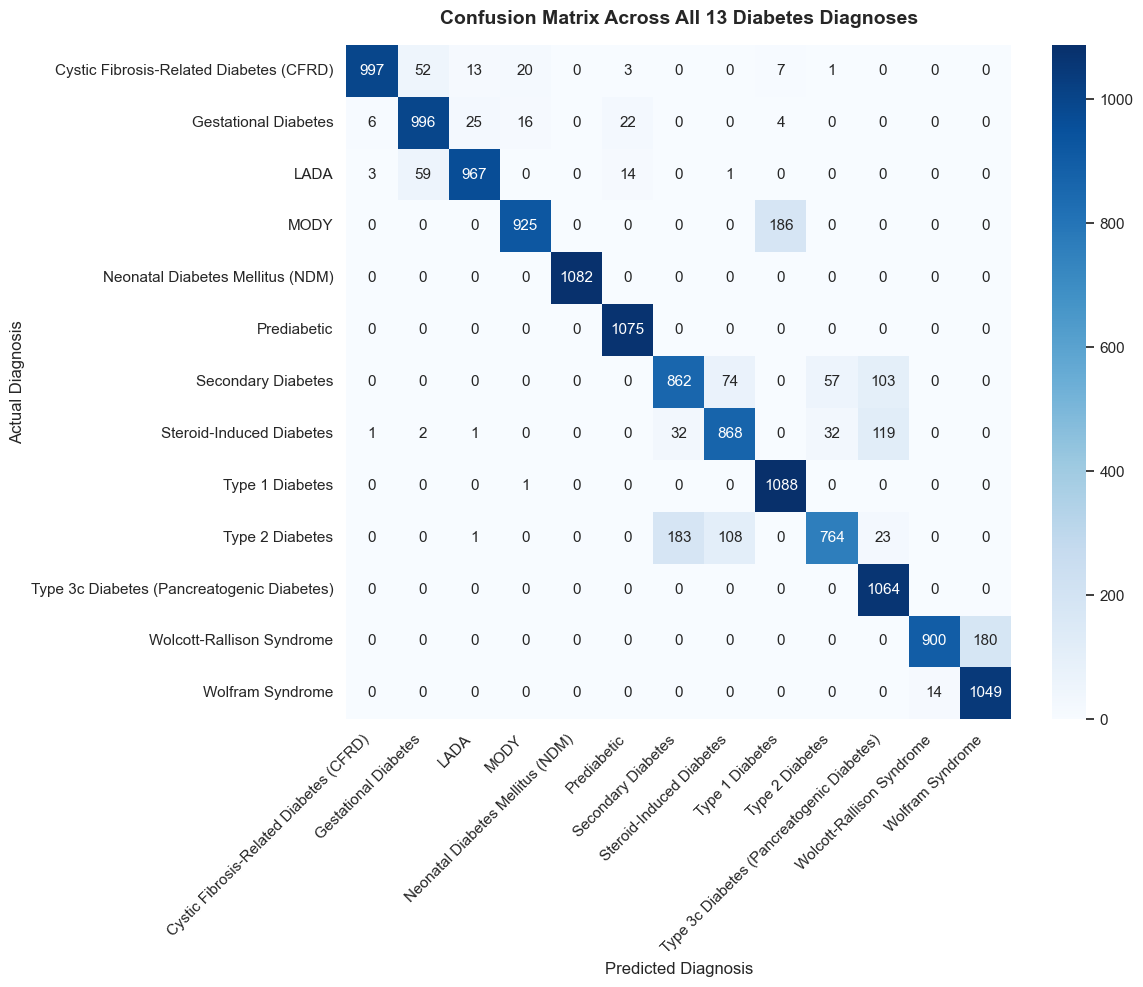

In [12]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_)
plt.title('Confusion Matrix Across All 13 Diabetes Diagnoses', fontsize=14, weight='bold', pad=15)
plt.xlabel('Predicted Diagnosis', fontsize=12)
plt.ylabel('Actual Diagnosis', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


---
## 7. Model & Pipeline Persistence
Saving the trained model, feature encoders, and population baselines using `joblib` for re-use and deployment.


In [13]:
# Save trained artifacts
joblib.dump(model, 'diabetes_rf_model.pkl')
joblib.dump({
    'encoders': encoders,
    'target_encoder': target_encoder,
    'feature_cols': feature_cols,
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'population_defaults': population_defaults,
    'cat_mappings': cat_mappings
}, 'diabetes_preprocessors.pkl')

print("✅ Model saved to: 'diabetes_rf_model.pkl'")
print("✅ Preprocessors saved to: 'diabetes_preprocessors.pkl'")


✅ Model saved to: 'diabetes_rf_model.pkl'
✅ Preprocessors saved to: 'diabetes_preprocessors.pkl'


---
## 8. Clinical Report Analysis Engine ("Diabetes or Not" + Subtype Diagnosis)
This section defines the core clinical decision engine:
- **Primary Screening: Diabetes or Not**:
  - 🟢 **NO DIABETES (NEGATIVE / NORMAL)**: When blood glucose is normal (<100 mg/dL), urinalysis is clean, and glucose tolerance is normal.
  - 🟡 **PREDIABETES (BORDERLINE / AT RISK)**: When fasting blood glucose is 100–125 mg/dL or glucose tolerance is impaired.
  - 🔴 **DIABETES POSITIVE (DIABETES DETECTED / YES)**: When fasting blood glucose ≥ 126 mg/dL or other diagnostic markers confirm diabetes.
- **Subtype Diagnosis**: If diabetes is present, determines whether it is Type 1, Type 2, Gestational, LADA, MODY, etc.
- **Biomarker Risk Stratification**: Compares vitals and lab numbers against international medical guidelines (ADA, AHA, WHO).
- **Clinical Action Plan**: Generates targeted confirmatory tests, specialist referrals, and emergency flags.


In [14]:
# Clinical Decision Support Engine with Primary "Diabetes or Not" Screening
def evaluate_diabetes_screening(report_data, ml_prediction, ml_confidence):
    """
    Determines whether the patient has diabetes or not, integrating clinical standards (ADA)
    with machine learning multi-class inferences.
    """
    glucose = float(report_data.get('Blood Glucose Levels', 100))
    gtt = str(report_data.get('Glucose Tolerance Test', 'Normal')).strip().lower()
    urine = str(report_data.get('Urine Test', 'Normal')).strip().lower()
    autoantibodies = str(report_data.get('Autoantibodies', 'Negative')).strip().lower()
    steroids = str(report_data.get('Steroid Use History', 'No')).strip().lower()
    cf = str(report_data.get('Cystic Fibrosis Diagnosis', 'No')).strip().lower()
    
    # 1. Clear Normal / Non-Diabetic Case:
    # Fasting glucose < 100 mg/dL, normal GTT, clean urine, negative autoantibodies, no secondary triggers
    if (glucose < 100 and gtt != 'abnormal' and 'glucose' not in urine and 
        'ketone' not in urine and autoantibodies != 'positive' and steroids != 'yes' and cf != 'yes'):
        has_diabetes = "NO"
        screening_verdict = "NO DIABETES (NEGATIVE / NORMAL)"
        status_color = "#10b981"
        status_bg = "linear-gradient(135deg, #059669, #10b981)"
        risk_level = "LOW RISK"
        diabetes_prob = min(8.0, max(1.0, (glucose / 100.0) * 8.0))
        primary_diagnosis = "Healthy Non-Diabetic Metabolic Profile"
        summary_explanation = f"Fasting blood glucose ({glucose:.0f} mg/dL) and all clinical markers are strictly within healthy physiological limits. No diabetes detected."

    # 2. Prediabetes / Impaired Fasting Glucose Case:
    elif (100 <= glucose <= 125) or (glucose < 100 and gtt == 'abnormal') or ("prediabetic" in ml_prediction.lower() and glucose < 126):
        has_diabetes = "PREDIABETES (AT RISK)"
        screening_verdict = "PREDIABETES (BORDERLINE / AT RISK)"
        status_color = "#f59e0b"
        status_bg = "linear-gradient(135deg, #d97706, #f59e0b)"
        risk_level = "MODERATE RISK"
        diabetes_prob = 45.0 + min(20.0, (glucose - 100) * 0.8)
        primary_diagnosis = "Prediabetes (Impaired Glucose Regulation)"
        summary_explanation = f"Fasting blood glucose ({glucose:.0f} mg/dL) reflects impaired fasting glucose / prediabetic state. Patient does not yet have established diabetes, but possesses heightened risk for progression."

    # 3. Diabetes Detected (Positive / YES):
    else:
        has_diabetes = "YES"
        screening_verdict = "DIABETES DETECTED: POSITIVE (YES)"
        status_color = "#ef4444"
        status_bg = "linear-gradient(135deg, #dc2626, #b91c1c)"
        risk_level = "HIGH RISK / CLINICALLY CONFIRMED"
        diabetes_prob = min(99.5, max(85.0, 75.0 + (glucose / 250.0) * 24.0))
        primary_diagnosis = ml_prediction
        summary_explanation = f"Elevated glycemic indicators (Fasting Glucose {glucose:.0f} mg/dL) confirm diabetes. Diagnostic pattern corresponds to {ml_prediction} with {ml_confidence:.1f}% confidence."

    return {
        'has_diabetes': has_diabetes,
        'screening_verdict': screening_verdict,
        'status_color': status_color,
        'status_bg': status_bg,
        'risk_level': risk_level,
        'diabetes_prob': diabetes_prob,
        'primary_diagnosis': primary_diagnosis,
        'summary_explanation': summary_explanation
    }


def analyze_patient_report(report_data, render_ui=True):
    """
    Analyzes patient medical report inputs: predicts whether there is diabetes or not,
    identifies specific subtype, and generates a structured clinical analysis.
    """
    # Build complete input vector using population defaults for missing fields
    processed_input = {}
    for col in feature_cols:
        if col in report_data and report_data[col] is not None:
            val = report_data[col]
            if col in cat_cols:
                str_val = str(val).strip().lower()
                matched_val = cat_mappings[col].get(str_val, population_defaults[col])
                processed_input[col] = matched_val
            else:
                try:
                    processed_input[col] = float(val)
                except (ValueError, TypeError):
                    processed_input[col] = population_defaults[col]
        else:
            processed_input[col] = population_defaults[col]
            
    # Prepare DataFrame matching exact training feature order
    input_df = pd.DataFrame([processed_input])[feature_cols]
    
    # Encode categorical fields
    for col in cat_cols:
        input_df[col] = encoders[col].transform(input_df[col].astype(str))
        
    # Model inference
    pred_idx = model.predict(input_df)[0]
    probas = model.predict_proba(input_df)[0]
    predicted_label = target_encoder.inverse_transform([pred_idx])[0]
    confidence = probas[pred_idx] * 100
    
    # Differential Diagnoses
    diff_df = pd.DataFrame({
        'Diagnosis': target_encoder.classes_,
        'Probability': probas * 100
    }).sort_values(by='Probability', ascending=False).reset_index(drop=True)
    
    # --- Primary "Diabetes or Not" Screening Evaluation ---
    screening = evaluate_diabetes_screening(processed_input, predicted_label, confidence)
    
    # --- Clinical Biomarker Evaluation (ADA / AHA / WHO Guidelines) ---
    glucose = float(processed_input['Blood Glucose Levels'])
    bp = float(processed_input['Blood Pressure'])
    bmi = float(processed_input['BMI'])
    insulin = float(processed_input['Insulin Levels'])
    chol = float(processed_input['Cholesterol Levels'])
    urine = str(processed_input['Urine Test'])
    autoantibodies = str(processed_input['Autoantibodies'])
    genetics = str(processed_input['Genetic Markers'])
    steroids = str(processed_input['Steroid Use History'])
    cf = str(processed_input['Cystic Fibrosis Diagnosis'])
    age = float(processed_input['Age'])
    gtt = str(processed_input['Glucose Tolerance Test'])
    
    biomarkers = []
    
    # Glucose evaluation
    if glucose < 100:
        g_badge = ("Normal Fasting (<100 mg/dL)", "#10b981", "#ecfdf5")
    elif 100 <= glucose <= 125:
        g_badge = ("Impaired Fasting Glucose / Prediabetes (100-125 mg/dL)", "#f59e0b", "#fffbeb")
    elif 126 <= glucose < 200:
        g_badge = ("Diabetic Hyperglycemia (126-199 mg/dL)", "#ef4444", "#fef2f2")
    else:
        g_badge = ("Severe Hyperglycemia (≥200 mg/dL)", "#991b1b", "#fee2e2")
    biomarkers.append(("Blood Glucose", f"{glucose:.0f} mg/dL", "< 100 mg/dL", g_badge))
    
    # Blood Pressure evaluation
    if bp < 120:
        bp_badge = ("Normal (<120 mmHg)", "#10b981", "#ecfdf5")
    elif 120 <= bp <= 129:
        bp_badge = ("Elevated (120-129 mmHg)", "#f59e0b", "#fffbeb")
    elif 130 <= bp <= 139:
        bp_badge = ("Stage 1 Hypertension (130-139 mmHg)", "#ea580c", "#fff7ed")
    else:
        bp_badge = ("Stage 2 Hypertension (≥140 mmHg)", "#ef4444", "#fef2f2")
    biomarkers.append(("Blood Pressure", f"{bp:.0f} mmHg", "< 120 mmHg", bp_badge))
    
    # BMI evaluation
    if bmi < 18.5:
        bmi_badge = ("Underweight (<18.5 kg/m²)", "#f59e0b", "#fffbeb")
    elif 18.5 <= bmi <= 24.9:
        bmi_badge = ("Healthy Weight (18.5-24.9 kg/m²)", "#10b981", "#ecfdf5")
    elif 25.0 <= bmi <= 29.9:
        bmi_badge = ("Overweight (25.0-29.9 kg/m²)", "#f59e0b", "#fffbeb")
    else:
        bmi_badge = ("Obese (≥30.0 kg/m²)", "#ef4444", "#fef2f2")
    biomarkers.append(("Body Mass Index (BMI)", f"{bmi:.1f} kg/m²", "18.5 - 24.9 kg/m²", bmi_badge))
    
    # Insulin evaluation
    if insulin < 10:
        ins_badge = ("Deficient (<10 μU/mL) - Beta-Cell Insufficiency", "#ea580c", "#fff7ed")
    elif 10 <= insulin <= 25:
        ins_badge = ("Normal Fasting (10-25 μU/mL)", "#10b981", "#ecfdf5")
    else:
        ins_badge = ("Hyperinsulinemia (>25 μU/mL) - Insulin Resistance", "#ef4444", "#fef2f2")
    biomarkers.append(("Insulin Level", f"{insulin:.0f} μU/mL", "10 - 25 μU/mL", ins_badge))
    
    # Cholesterol evaluation
    if chol < 200:
        chol_badge = ("Desirable (<200 mg/dL)", "#10b981", "#ecfdf5")
    elif 200 <= chol <= 239:
        chol_badge = ("Borderline High (200-239 mg/dL)", "#f59e0b", "#fffbeb")
    else:
        chol_badge = ("High / Hypercholesterolemia (≥240 mg/dL)", "#ef4444", "#fef2f2")
    biomarkers.append(("Cholesterol", f"{chol:.0f} mg/dL", "< 200 mg/dL", chol_badge))
    
    # Urine Test
    if "ketone" in urine.lower():
        u_badge = ("🚨 Ketonuria - Critical DKA Risk Indicator", "#991b1b", "#fee2e2")
    elif "glucose" in urine.lower():
        u_badge = ("Glycosuria - Exceeds Renal Threshold", "#ef4444", "#fef2f2")
    elif "protein" in urine.lower():
        u_badge = ("Proteinuria - Nephropathy / Renal Stress Risk", "#ea580c", "#fff7ed")
    else:
        u_badge = ("Normal - Clean Urinalysis", "#10b981", "#ecfdf5")
    biomarkers.append(("Urine Analysis", urine, "Negative / Normal", u_badge))
    
    # Diagnostic Markers
    ab_badge = ("Autoimmune Etiology Positive", "#ef4444", "#fef2f2") if autoantibodies.lower() == "positive" else ("Negative (Non-Autoimmune)", "#10b981", "#ecfdf5")
    biomarkers.append(("Autoantibodies", autoantibodies, "Negative", ab_badge))
    
    gtt_badge = ("Abnormal Glucose Clearance", "#ef4444", "#fef2f2") if gtt.lower() == "abnormal" else ("Normal Clearance", "#10b981", "#ecfdf5")
    biomarkers.append(("Glucose Tolerance (OGTT)", gtt, "Normal", gtt_badge))

    # --- Identify Specific Patient Diagnostic Drivers ---
    drivers = []
    if screening['has_diabetes'] == "NO":
        drivers.append("Fasting blood glucose (<100 mg/dL) is within optimal healthy range.")
        drivers.append("Oral glucose tolerance and urinalysis confirm preserved glycemic homeostasis.")
        drivers.append("No active autoimmune or secondary metabolic hyperglycemic factors detected.")
    else:
        if glucose >= 126:
            drivers.append(f"Elevated fasting blood glucose ({glucose:.0f} mg/dL) confirms hyperglycemic diagnostic state.")
        elif glucose >= 100:
            drivers.append(f"Impaired fasting glucose ({glucose:.0f} mg/dL) points towards impaired glucose regulation / prediabetes.")
            
        if autoantibodies.lower() == "positive":
            drivers.append("Positive pancreatic autoantibodies indicate autoimmune-mediated destruction of pancreatic islet beta-cells.")
            
        if steroids.lower() == "yes":
            drivers.append("History of corticosteroid therapy identified as a potent pharmacologic trigger of steroid-induced diabetes.")
            
        if cf.lower() == "yes":
            drivers.append("Comorbid Cystic Fibrosis diagnosis aligns with Cystic Fibrosis-Related Diabetes (CFRD) pathogenesis.")
            
        if bmi >= 30:
            drivers.append(f"Obese BMI ({bmi:.1f} kg/m²) indicates pronounced adiposity-mediated peripheral insulin resistance.")
            
        if insulin > 25:
            drivers.append(f"Elevated fasting insulin ({insulin:.0f} μU/mL) reflects marked compensatory hyperinsulinemia.")
        elif insulin < 10:
            drivers.append(f"Depleted circulating insulin ({insulin:.0f} μU/mL) reflects severe beta-cell secretory exhaustion.")
            
        if "ketone" in urine.lower():
            drivers.append("Presence of ketones in urine reflects rapid fatty acid oxidation and cellular insulin deprivation.")
            
        if str(processed_input['Family History']).lower() == "yes":
            drivers.append("Strong familial diabetic history indicates significant genetic susceptibility.")

    # --- Recommendations & Alerts ---
    urgent_flags = []
    if "ketone" in urine.lower() and glucose >= 180:
        urgent_flags.append("🚨 CRITICAL ALERT: Ketonuria detected in conjunction with hyperglycemia. Immediately evaluate for Diabetic Ketoacidosis (DKA)!")
    if bp >= 160:
        urgent_flags.append("🚨 URGENT: Severe hypertensive range detected. Rapid medical evaluation advised to mitigate cardiovascular emergency.")

    recs = []
    if screening['has_diabetes'] == "NO":
        recs.append("Routine annual wellness examination and preventative fasting blood glucose check.")
        recs.append("Maintain healthy lifestyle: balanced nutrient-dense diet and 150 minutes of weekly physical activity.")
        recs.append("No antidiabetic pharmacotherapy or therapeutic glucose-lowering interventions indicated.")
    elif screening['has_diabetes'] == "PREDIABETES (AT RISK)":
        recs.append("Enroll in a structured Diabetes Prevention Program (DPP) targeting 5-7% intentional weight reduction.")
        recs.append("Adopt low-glycemic Mediterranean or DASH dietary pattern; reduce refined sugars and simple carbs.")
        recs.append("Engage in regular aerobic exercise (e.g. brisk walking) at least 30 minutes daily.")
        recs.append("Repeat fasting plasma glucose and laboratory HbA1c testing within 3 to 6 months.")
    else:
        pred_lower = predicted_label.lower()
        if "type 1" in pred_lower:
            recs.append("Immediate Endocrinologist referral for basal-bolus insulin regimen initiation and titration.")
            recs.append("Order confirmatory GAD65, IA-2, and ZnT8 autoantibodies with fasting C-peptide.")
            recs.append("Deploy Continuous Glucose Monitoring (CGM) and initiate carbohydrate-to-insulin ratio education.")
        elif "type 2" in pred_lower:
            recs.append("Comprehensive clinical consultation with an Endocrinologist or primary care physician.")
            recs.append("Laboratory workup: Fasting HbA1c (glycated hemoglobin), lipid panel, and urine albumin-to-creatinine ratio (uACR).")
            recs.append("Target at least 150 minutes/week of moderate physical activity paired with medical nutrition therapy.")
            recs.append("Evaluate guideline-directed pharmacotherapy (e.g. Metformin, SGLT2 inhibitors, or GLP-1 receptor agonists).")
        elif "gestational" in pred_lower:
            recs.append("Urgent Maternal-Fetal Medicine (MFM) and Certified Diabetes Educator referral.")
            recs.append("Structured blood glucose monitoring (fasting + 1-hr/2-hr postprandial) 4 times daily.")
            recs.append("Postpartum follow-up: Repeat 75g 2-hour OGTT at 4 to 12 weeks postpartum to screen for chronic dysglycemia.")
        elif "steroid" in pred_lower:
            recs.append("Liaise with prescribing physician for corticosteroid dose titration or steroid-sparing alternatives.")
            recs.append("Tailor blood glucose monitoring to afternoon and post-dinner periods when steroid hyperglycemia peaks.")
        elif "cfrd" in pred_lower or "cystic fibrosis" in pred_lower:
            recs.append("Coordinate multidisciplinary follow-up with CF pulmonologist and CF-expert endocrinologist.")
            recs.append("Annual 2-hour oral glucose tolerance test (OGTT) as per clinical guidelines.")
            recs.append("Important: Avoid fat/caloric restriction in CF patients due to high respiratory metabolic needs.")
        elif "lada" in pred_lower:
            recs.append("Endocrinology consult: LADA entails progressive autoimmune beta-cell failure requiring proactive insulin planning.")
            recs.append("Monitor fasting and post-meal C-peptide levels; avoid sulfonylurea monotherapy.")
        else:
            recs.append("Consult an endocrinologist and medical geneticist for detailed subtype profiling.")
            recs.append("Order comprehensive confirmatory metabolic panel (HbA1c, fasting insulin, C-peptide).")
            recs.append("Maintain routine blood glucose logging and lifestyle optimization.")

    result = {
        'has_diabetes': screening['has_diabetes'],
        'screening_verdict': screening['screening_verdict'],
        'risk_level': screening['risk_level'],
        'diabetes_probability_pct': screening['diabetes_prob'],
        'predicted_subtype': screening['primary_diagnosis'],
        'subtype_confidence_pct': confidence if screening['has_diabetes'] != "NO" else (100.0 - screening['diabetes_prob']),
        'differentials': diff_df.head(3),
        'biomarkers': biomarkers,
        'drivers': drivers,
        'recommendations': recs,
        'urgent_flags': urgent_flags,
        'input_data': processed_input
    }
    
    # --- Rich HTML Presentation in Jupyter ---
    if render_ui:
        html_output = f"""
        <div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
                    max-width: 900px; border: 1px solid #e2e8f0; border-radius: 12px; padding: 24px;
                    background: #ffffff; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.1); margin: 15px 0;">
            
            <!-- Header -->
            <div style="border-bottom: 2px solid #3b82f6; padding-bottom: 12px; margin-bottom: 20px;">
                <div style="display: flex; justify-content: space-between; align-items: center;">
                    <h2 style="margin: 0; color: #1e293b; font-size: 24px;">📋 Clinical Laboratory Report Analysis</h2>
                    <span style="background: #eff6ff; color: #1d4ed8; padding: 4px 12px; border-radius: 9999px;
                                 font-size: 13px; font-weight: 600; border: 1px solid #bfdbfe;">
                        AI Diagnostic Assistant
                    </span>
                </div>
                <p style="margin: 4px 0 0 0; color: #64748b; font-size: 13px;">
                    Automated Diabetes Screening ("Diabetes or Not") & Subtype Classification
                </p>
            </div>
        """
        
        # Urgent Alerts
        if urgent_flags:
            html_output += "<div style='margin-bottom: 20px;'>"
            for alert in urgent_flags:
                html_output += f"""
                <div style="background-color: #fee2e2; border-left: 5px solid #dc2626; color: #991b1b;
                            padding: 12px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; margin-bottom: 8px;">
                    {alert}
                </div>
                """
            html_output += "</div>"
            
        # PRIMARY SCREENING VERDICT BANNER (PROMINENT AT TOP)
        html_output += f"""
        <div style="background: {screening['status_bg']}; color: white; padding: 20px 24px;
                    border-radius: 10px; margin-bottom: 20px; box-shadow: 0 4px 6px rgba(0,0,0,0.1);">
            <div style="font-size: 12px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.08em; opacity: 0.9;">
                PRIMARY SCREENING RESULT: DOES THE PATIENT HAVE DIABETES?
            </div>
            <div style="font-size: 28px; font-weight: 800; margin: 6px 0;">
                {screening['screening_verdict']}
            </div>
            <div style="font-size: 14px; opacity: 0.95; line-height: 1.4;">
                <strong>Has Diabetes:</strong> {screening['has_diabetes']} &nbsp;|&nbsp;
                <strong>Estimated Risk:</strong> {screening['risk_level']} &nbsp;|&nbsp;
                <strong>Probability:</strong> {screening['diabetes_prob']:.1f}%
            </div>
            <div style="font-size: 13px; margin-top: 6px; opacity: 0.9; font-style: italic;">
                {screening['summary_explanation']}
            </div>
        </div>
        """
        
        # Subtype Breakdown
        if screening['has_diabetes'] != "NO":
            html_output += f"""
            <div style="display: grid; grid-template-columns: 2fr 1fr; gap: 16px; margin-bottom: 24px;">
                <div style="background: #f8fafc; border: 1px solid #cbd5e1; padding: 18px; border-radius: 10px;">
                    <div style="font-size: 12px; text-transform: uppercase; font-weight: 700; color: #475569;">
                        Specific Clinical Subtype Classification
                    </div>
                    <div style="font-size: 24px; font-weight: 800; color: #0f172a; margin: 6px 0;">
                        {predicted_label}
                    </div>
                    <div style="font-size: 13px; color: #334155;">
                        Subtype Diagnostic Confidence: <strong>{confidence:.1f}%</strong>
                    </div>
                </div>
                
                <div style="background: #f8fafc; border: 1px solid #e2e8f0; padding: 16px; border-radius: 10px;">
                    <div style="font-size: 12px; font-weight: 700; color: #475569; text-transform: uppercase; margin-bottom: 8px;">
                        Differential Diagnoses
                    </div>
            """
            for _, row in diff_df.head(3).iterrows():
                prob = row['Probability']
                html_output += f"""
                    <div style="margin-bottom: 6px; font-size: 13px;">
                        <div style="display: flex; justify-content: space-between; margin-bottom: 2px;">
                            <span style="color: #1e293b; font-weight: 500;">{row['Diagnosis']}</span>
                            <span style="color: #64748b; font-weight: 600;">{prob:.1f}%</span>
                        </div>
                        <div style="background: #e2e8f0; height: 6px; border-radius: 3px; overflow: hidden;">
                            <div style="background: #3b82f6; width: {prob}%; height: 100%;"></div>
                        </div>
                    </div>
                """
            html_output += """
                </div>
            </div>
            """
            
        # Biomarkers Table
        html_output += """
        <div style="margin-bottom: 24px;">
            <h3 style="color: #1e293b; font-size: 17px; margin: 0 0 12px 0;">🔬 Patient Biomarkers & Reference Evaluation</h3>
            <table style="width: 100%; border-collapse: collapse; font-size: 13px; text-align: left;">
                <thead>
                    <tr style="background-color: #f1f5f9; border-bottom: 2px solid #cbd5e1;">
                        <th style="padding: 10px 12px; color: #334155; font-weight: 600;">Biomarker / Test</th>
                        <th style="padding: 10px 12px; color: #334155; font-weight: 600;">Patient Value</th>
                        <th style="padding: 10px 12px; color: #334155; font-weight: 600;">Normal Reference</th>
                        <th style="padding: 10px 12px; color: #334155; font-weight: 600;">Clinical Assessment</th>
                    </tr>
                </thead>
                <tbody>
        """
        for name, val, ref, (status_text, text_col, bg_col) in biomarkers:
            html_output += f"""
                <tr style="border-bottom: 1px solid #f1f5f9;">
                    <td style="padding: 9px 12px; font-weight: 600; color: #1e293b;">{name}</td>
                    <td style="padding: 9px 12px; color: #0f172a; font-family: monospace; font-size: 13px;">{val}</td>
                    <td style="padding: 9px 12px; color: #64748b;">{ref}</td>
                    <td style="padding: 9px 12px;">
                        <span style="background-color: {bg_col}; color: {text_col}; padding: 3px 8px;
                                     border-radius: 4px; font-weight: 600; font-size: 12px;">
                            {status_text}
                        </span>
                    </td>
                </tr>
            """
        html_output += """
                </tbody>
            </table>
        </div>
        """
        
        # Diagnostic Drivers & Recommendations Grid
        html_output += """
        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 18px; margin-bottom: 16px;">
            <div style="background: #f8fafc; border: 1px solid #e2e8f0; border-radius: 8px; padding: 16px;">
                <h4 style="color: #0f172a; margin: 0 0 10px 0; font-size: 15px;">🔍 Key Contributing Diagnostic Drivers</h4>
                <ul style="margin: 0; padding-left: 20px; color: #334155; font-size: 13px; line-height: 1.6;">
        """
        for driver in drivers:
            html_output += f"<li style='margin-bottom: 6px;'>{driver}</li>"
        html_output += """
                </ul>
            </div>
            
            <div style="background: #f0fdf4; border: 1px solid #bbf7d0; border-radius: 8px; padding: 16px;">
                <h4 style="color: #166534; margin: 0 0 10px 0; font-size: 15px;">🩺 Clinical Recommendations & Next Steps</h4>
                <ul style="margin: 0; padding-left: 20px; color: #166534; font-size: 13px; line-height: 1.6;">
        """
        for rec in recs:
            html_output += f"<li style='margin-bottom: 6px;'>{rec}</li>"
        html_output += """
                </ul>
            </div>
        </div>
        
        <!-- Disclaimer -->
        <div style="font-size: 11px; color: #94a3b8; text-align: center; border-top: 1px solid #f1f5f9; padding-top: 10px;">
            ⚠️ <em>Decision Support Disclaimer: This automated report is generated using statistical machine learning models. Clinical correlation by a licensed physician is essential for therapeutic decisions.</em>
        </div>
        
        </div>
        """
        display(HTML(html_output))
        
    return result

def print_clinical_summary(analysis):
    """Prints a formatted text-based clinical summary report."""
    print("=" * 70)
    print(f"🎯 PRIMARY SCREENING RESULT: {analysis['screening_verdict']}")
    print(f"   • HAS DIABETES:       {analysis['has_diabetes']}")
    print(f"   • ESTIMATED RISK:     {analysis['risk_level']} (Probability: {analysis['diabetes_probability_pct']:.1f}%)")
    print(f"   • CLINICAL DIAGNOSIS: {analysis['predicted_subtype']} (Confidence: {analysis['subtype_confidence_pct']:.1f}%)")
    print("=" * 70)
    print("\n[PATIENT BIOMARKER & LAB EVALUATION]")
    for name, val, ref, (status_text, _, _) in analysis['biomarkers']:
        clean_status = status_text.replace('🟢', '').replace('🟡', '').replace('🟠', '').replace('🔴', '').replace('🚨', '').strip()
        print(f"  • {name:28}: {str(val):12} [Ref: {ref:16}] -> {clean_status}")
    print("\n[KEY DIAGNOSTIC DRIVERS IDENTIFIED]")
    for d in analysis['drivers']:
        print(f"  ▶ {d}")
    print("\n[CLINICAL RECOMMENDATIONS & NEXT STEPS]")
    for r in analysis['recommendations']:
        print(f"  ✓ {r}")
    if analysis['urgent_flags']:
        print("\n[URGENT CLINICAL ALERTS]")
        for a in analysis['urgent_flags']:
            clean_alert = a.replace('🚨', '').strip()
            print(f"  ! {clean_alert}")
    print("=" * 70)

print("✅ Clinical Decision Support Engine registered successfully.")


✅ Clinical Decision Support Engine registered successfully.


---
## 9. Interactive Medical Report Input & Analysis
Here you can input any patient report directly and immediately receive the multi-dimensional clinical analysis!

We provide multiple convenient ways to enter data:
1. **Interactive Form (GUI)**: Form controls with sliders and dropdown menus inside Jupyter.
2. **Direct Dictionary Call**: Edit the values in a python dictionary and execute.
3. **Pre-configured Clinical Test Cases**: Run realistic test cases across various presentations (Normal, Prediabetic, Type 2, Type 1, Gestational).
4. **Step-by-Step Interactive CLI Prompt**: Terminal-style input prompts.


### Method 1: Interactive GUI Report Entry Form
Adjust the lab values, vitals, and diagnostic test results using the controls below, then click **⚡ Analyze Medical Report**.


In [15]:
# 1. Interactive Form Controls
# Vitals & Demographics
w_age = widgets.IntSlider(value=45, min=0, max=90, step=1, description='Age (yrs):')
w_glucose = widgets.IntSlider(value=180, min=60, max=350, step=1, description='Glucose (mg/dL):', style={'description_width': 'initial'})
w_bp = widgets.IntSlider(value=135, min=60, max=220, step=1, description='BP (mmHg):', style={'description_width': 'initial'})
w_bmi = widgets.FloatSlider(value=31.2, min=12.0, max=50.0, step=0.1, description='BMI (kg/m²):', style={'description_width': 'initial'})
w_insulin = widgets.IntSlider(value=35, min=2, max=80, step=1, description='Insulin (μU/mL):', style={'description_width': 'initial'})
w_chol = widgets.IntSlider(value=220, min=100, max=350, step=1, description='Cholesterol:', style={'description_width': 'initial'})
w_waist = widgets.IntSlider(value=38, min=20, max=60, step=1, description='Waist (in):', style={'description_width': 'initial'})

# Diagnostic Laboratory Tests
w_urine = widgets.Dropdown(options=['Normal', 'Glucose Present', 'Ketones Present', 'Protein Present'], value='Glucose Present', description='Urine Test:')
w_auto = widgets.Dropdown(options=['Negative', 'Positive'], value='Negative', description='Autoantibodies:')
w_gen_markers = widgets.Dropdown(options=['Negative', 'Positive'], value='Negative', description='Genetic Markers:')
w_gen_testing = widgets.Dropdown(options=['Negative', 'Positive'], value='Negative', description='Genetic Testing:')
w_gtt = widgets.Dropdown(options=['Normal', 'Abnormal'], value='Abnormal', description='Glucose Tolerance:')
w_liver = widgets.Dropdown(options=['Normal', 'Abnormal'], value='Normal', description='Liver Function:')
w_pancreatic = widgets.IntSlider(value=65, min=10, max=100, step=1, description='Pancreas Health:', style={'description_width': 'initial'})
w_pulmonary = widgets.IntSlider(value=75, min=30, max=100, step=1, description='Pulmonary Func:', style={'description_width': 'initial'})
w_enzymes = widgets.IntSlider(value=50, min=10, max=100, step=1, description='Digestive Enzymes:', style={'description_width': 'initial'})

# Medical History & Lifestyle
w_family = widgets.Dropdown(options=['No', 'Yes'], value='Yes', description='Family History:')
w_steroids = widgets.Dropdown(options=['No', 'Yes'], value='No', description='Steroid History:')
w_cf = widgets.Dropdown(options=['No', 'Yes'], value='No', description='Cystic Fibrosis:')
w_activity = widgets.Dropdown(options=['Low', 'Moderate', 'High'], value='Low', description='Physical Activity:')
w_diet = widgets.Dropdown(options=['Healthy', 'Unhealthy'], value='Unhealthy', description='Dietary Habits:')
w_smoking = widgets.Dropdown(options=['Non-Smoker', 'Smoker'], value='Non-Smoker', description='Smoking:')
w_alcohol = widgets.Dropdown(options=['Low', 'Moderate', 'High'], value='Low', description='Alcohol:')
w_pcos = widgets.Dropdown(options=['No', 'Yes'], value='No', description='History of PCOS:')
w_prev_gdm = widgets.Dropdown(options=['No', 'Yes'], value='No', description='Previous GDM:')
w_pregnancy = widgets.Dropdown(options=['Normal', 'Complications'], value='Normal', description='Pregnancy Hist:')
w_gest_wt = widgets.IntSlider(value=0, min=0, max=40, step=1, description='Pregnancy Wt Gain:', style={'description_width': 'initial'})
w_birth_wt = widgets.IntSlider(value=3200, min=1500, max=4500, step=50, description='Birth Weight (g):', style={'description_width': 'initial'})
w_early_onset = widgets.Dropdown(options=['No', 'Yes'], value='No', description='Early Symptoms:')
w_ethnicity = widgets.Dropdown(options=['Low Risk', 'High Risk'], value='High Risk', description='Ethnicity Risk:')
w_socio = widgets.Dropdown(options=['Low', 'Medium', 'High'], value='Medium', description='Socioeconomic:')
w_env = widgets.Dropdown(options=['Absent', 'Present'], value='Absent', description='Environmental:')
w_neuro = widgets.IntSlider(value=1, min=1, max=3, step=1, description='Neurological:')

# Layout Organization
tab_vitals = widgets.VBox([w_age, w_glucose, w_bp, w_bmi, w_insulin, w_chol, w_waist])
tab_labs = widgets.VBox([w_urine, w_auto, w_gen_markers, w_gen_testing, w_gtt, w_liver, w_pancreatic, w_pulmonary, w_enzymes])
tab_history = widgets.VBox([w_family, w_steroids, w_cf, w_activity, w_diet, w_smoking, w_alcohol, w_pcos, w_prev_gdm, w_pregnancy, w_gest_wt, w_birth_wt, w_early_onset, w_ethnicity, w_socio, w_env, w_neuro])

form_tabs = widgets.Tab(children=[tab_vitals, tab_labs, tab_history])
form_tabs.set_title(0, '🩸 Vitals & Demographics')
form_tabs.set_title(1, '🧪 Diagnostic Labs')
form_tabs.set_title(2, '📋 History & Lifestyle')

analyze_button = widgets.Button(
    description='⚡ Analyze Medical Report',
    button_style='primary',
    tooltip='Click to predict diabetes status and analyze report',
    icon='stethoscope',
    layout=widgets.Layout(width='300px', height='45px', margin='15px 0')
)

output_area = widgets.Output()

def on_analyze_clicked(b):
    output_area.clear_output()
    patient_report = {
        'Age': w_age.value,
        'Blood Glucose Levels': w_glucose.value,
        'Blood Pressure': w_bp.value,
        'BMI': w_bmi.value,
        'Insulin Levels': w_insulin.value,
        'Cholesterol Levels': w_chol.value,
        'Waist Circumference': w_waist.value,
        'Urine Test': w_urine.value,
        'Autoantibodies': w_auto.value,
        'Genetic Markers': w_gen_markers.value,
        'Genetic Testing': w_gen_testing.value,
        'Glucose Tolerance Test': w_gtt.value,
        'Liver Function Tests': w_liver.value,
        'Pancreatic Health': w_pancreatic.value,
        'Pulmonary Function': w_pulmonary.value,
        'Digestive Enzyme Levels': w_enzymes.value,
        'Family History': w_family.value,
        'Steroid Use History': w_steroids.value,
        'Cystic Fibrosis Diagnosis': w_cf.value,
        'Physical Activity': w_activity.value,
        'Dietary Habits': w_diet.value,
        'Smoking Status': w_smoking.value,
        'Alcohol Consumption': w_alcohol.value,
        'History of PCOS': w_pcos.value,
        'Previous Gestational Diabetes': w_prev_gdm.value,
        'Pregnancy History': w_pregnancy.value,
        'Weight Gain During Pregnancy': w_gest_wt.value,
        'Birth Weight': w_birth_wt.value,
        'Early Onset Symptoms': w_early_onset.value,
        'Ethnicity': w_ethnicity.value,
        'Socioeconomic Factors': w_socio.value,
        'Environmental Factors': w_env.value,
        'Neurological Assessments': w_neuro.value
    }
    with output_area:
        analyze_patient_report(patient_report, render_ui=True)

analyze_button.on_click(on_analyze_clicked)

display(form_tabs, analyze_button, output_area)


Button(button_style='primary', description='⚡ Analyze Medical Report', icon='stethoscope', layout=Layout(heigh…

Output()

### Method 2: Direct Dictionary Input (Edit & Run)
You can directly input any patient's lab report by modifying the values in the dictionary below and executing the cell:


In [16]:
# Modify these values according to the patient's lab report:
custom_patient_report = {
    'Blood Glucose Levels': 195,              # mg/dL (Normal: < 100)
    'Blood Pressure': 142,                    # mmHg (Normal: < 120)
    'BMI': 33.4,                              # kg/m² (Normal: 18.5 - 24.9)
    'Insulin Levels': 38,                     # μU/mL (Normal: 10 - 25)
    'Cholesterol Levels': 245,                # mg/dL (Normal: < 200)
    'Age': 54,                                # years
    'Waist Circumference': 42,                # inches
    
    # Lab & Diagnostic Tests
    'Urine Test': 'Glucose Present',          # 'Normal', 'Glucose Present', 'Ketones Present', 'Protein Present'
    'Autoantibodies': 'Negative',             # 'Positive' or 'Negative'
    'Genetic Markers': 'Negative',            # 'Positive' or 'Negative'
    'Genetic Testing': 'Negative',            # 'Positive' or 'Negative'
    'Glucose Tolerance Test': 'Abnormal',     # 'Normal' or 'Abnormal'
    'Liver Function Tests': 'Normal',         # 'Normal' or 'Abnormal'
    
    # Medical History & Lifestyle
    'Family History': 'Yes',                  # 'Yes' or 'No'
    'Steroid Use History': 'No',              # 'Yes' or 'No'
    'Cystic Fibrosis Diagnosis': 'No',        # 'Yes' or 'No'
    'Physical Activity': 'Low',               # 'Low', 'Moderate', 'High'
    'Dietary Habits': 'Unhealthy',            # 'Healthy' or 'Unhealthy'
    'Smoking Status': 'Smoker',               # 'Smoker' or 'Non-Smoker'
    'Alcohol Consumption': 'Moderate',        # 'Low', 'Moderate', 'High'
    'Pancreatic Health': 70,                  # Score 10 - 100
    'Pulmonary Function': 80,                 # Score 30 - 100
    'Early Onset Symptoms': 'No'              # 'Yes' or 'No'
}

# Run the analysis
analysis_result = analyze_patient_report(custom_patient_report, render_ui=True)


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,195 mg/dL,< 100 mg/dL,Diabetic Hyperglycemia (126-199 mg/dL)
Blood Pressure,142 mmHg,< 120 mmHg,Stage 2 Hypertension (≥140 mmHg)
Body Mass Index (BMI),33.4 kg/m²,18.5 - 24.9 kg/m²,Obese (≥30.0 kg/m²)
Insulin Level,38 μU/mL,10 - 25 μU/mL,Hyperinsulinemia (>25 μU/mL) - Insulin Resistance
Cholesterol,245 mg/dL,< 200 mg/dL,High / Hypercholesterolemia (≥240 mg/dL)
Urine Analysis,Glucose Present,Negative / Normal,Glycosuria - Exceeds Renal Threshold
Autoantibodies,Negative,Negative,Negative (Non-Autoimmune)
Glucose Tolerance (OGTT),Abnormal,Normal,Abnormal Glucose Clearance


### Method 3: Pre-Configured Clinical Test Cases (Screening Demonstration)
Below we demonstrate the system analyzing distinct clinical scenarios:
1. **Case 1 (Healthy Control)**: Normal vitals and blood sugar -> **NO DIABETES (NEGATIVE)**
2. **Case 2 (Prediabetic)**: Borderline fasting glucose of 112 mg/dL -> **PREDIABETES (AT RISK)**
3. **Case 3 (Type 2 Diabetes)**: Hyperglycemia with metabolic syndrome -> **DIABETES POSITIVE (YES)**
4. **Case 4 (Type 1 Diabetes)**: Pediatric onset with autoantibodies & ketones -> **DIABETES POSITIVE (YES)**


In [17]:
# Case 1: Healthy Non-Diabetic Patient
case_healthy = {
    'Age': 28,
    'Blood Glucose Levels': 88,
    'BMI': 22.1,
    'Blood Pressure': 114,
    'Insulin Levels': 14,
    'Cholesterol Levels': 168,
    'Glucose Tolerance Test': 'Normal',
    'Urine Test': 'Normal',
    'Autoantibodies': 'Negative',
    'Physical Activity': 'High',
    'Dietary Habits': 'Healthy',
    'Family History': 'No',
    'Steroid Use History': 'No',
    'Cystic Fibrosis Diagnosis': 'No'
}

print("RUNNING SCREENING FOR CASE 1 (Healthy Normal Profile):")
analyze_patient_report(case_healthy, render_ui=True);


RUNNING SCREENING FOR CASE 1 (Healthy Normal Profile):


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,88 mg/dL,< 100 mg/dL,Normal Fasting (<100 mg/dL)
Blood Pressure,114 mmHg,< 120 mmHg,Normal (<120 mmHg)
Body Mass Index (BMI),22.1 kg/m²,18.5 - 24.9 kg/m²,Healthy Weight (18.5-24.9 kg/m²)
Insulin Level,14 μU/mL,10 - 25 μU/mL,Normal Fasting (10-25 μU/mL)
Cholesterol,168 mg/dL,< 200 mg/dL,Desirable (<200 mg/dL)
Urine Analysis,Normal,Negative / Normal,Normal - Clean Urinalysis
Autoantibodies,Negative,Negative,Negative (Non-Autoimmune)
Glucose Tolerance (OGTT),Normal,Normal,Normal Clearance


In [18]:
# Case 2: Suspected Prediabetes Patient
case_prediabetic = {
    'Age': 42,
    'Blood Glucose Levels': 112,
    'Insulin Levels': 22,
    'BMI': 27.8,
    'Blood Pressure': 126,
    'Cholesterol Levels': 208,
    'Autoantibodies': 'Negative',
    'Urine Test': 'Normal',
    'Glucose Tolerance Test': 'Abnormal',
    'Physical Activity': 'Low',
    'Dietary Habits': 'Unhealthy',
    'Family History': 'Yes'
}

print("RUNNING SCREENING FOR CASE 2 (Borderline Dysglycemia):")
analyze_patient_report(case_prediabetic, render_ui=True);


RUNNING SCREENING FOR CASE 2 (Borderline Dysglycemia):


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,112 mg/dL,< 100 mg/dL,Impaired Fasting Glucose / Prediabetes (100-125 mg/dL)
Blood Pressure,126 mmHg,< 120 mmHg,Elevated (120-129 mmHg)
Body Mass Index (BMI),27.8 kg/m²,18.5 - 24.9 kg/m²,Overweight (25.0-29.9 kg/m²)
Insulin Level,22 μU/mL,10 - 25 μU/mL,Normal Fasting (10-25 μU/mL)
Cholesterol,208 mg/dL,< 200 mg/dL,Borderline High (200-239 mg/dL)
Urine Analysis,Normal,Negative / Normal,Normal - Clean Urinalysis
Autoantibodies,Negative,Negative,Negative (Non-Autoimmune)
Glucose Tolerance (OGTT),Abnormal,Normal,Abnormal Glucose Clearance


In [19]:
# Case 3: Suspected Type 2 Diabetes Patient
case_type2 = {
    'Age': 56,
    'Blood Glucose Levels': 190,
    'Insulin Levels': 36,
    'BMI': 33.2,
    'Blood Pressure': 142,
    'Cholesterol Levels': 235,
    'Autoantibodies': 'Negative',
    'Urine Test': 'Glucose Present',
    'Glucose Tolerance Test': 'Abnormal',
    'Physical Activity': 'Low',
    'Dietary Habits': 'Unhealthy',
    'Family History': 'Yes'
}

print("RUNNING SCREENING FOR CASE 3 (Metabolic Hyperglycemia):")
analyze_patient_report(case_type2, render_ui=True);


RUNNING SCREENING FOR CASE 3 (Metabolic Hyperglycemia):


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,190 mg/dL,< 100 mg/dL,Diabetic Hyperglycemia (126-199 mg/dL)
Blood Pressure,142 mmHg,< 120 mmHg,Stage 2 Hypertension (≥140 mmHg)
Body Mass Index (BMI),33.2 kg/m²,18.5 - 24.9 kg/m²,Obese (≥30.0 kg/m²)
Insulin Level,36 μU/mL,10 - 25 μU/mL,Hyperinsulinemia (>25 μU/mL) - Insulin Resistance
Cholesterol,235 mg/dL,< 200 mg/dL,Borderline High (200-239 mg/dL)
Urine Analysis,Glucose Present,Negative / Normal,Glycosuria - Exceeds Renal Threshold
Autoantibodies,Negative,Negative,Negative (Non-Autoimmune)
Glucose Tolerance (OGTT),Abnormal,Normal,Abnormal Glucose Clearance


In [20]:
# Case 4: Suspected Type 1 Diabetes Patient
case_type1 = {
    'Age': 11,
    'Blood Glucose Levels': 240,
    'Insulin Levels': 6,
    'BMI': 16.5,
    'Autoantibodies': 'Positive',
    'Urine Test': 'Ketones Present',
    'Early Onset Symptoms': 'Yes',
    'Genetic Markers': 'Positive',
    'Glucose Tolerance Test': 'Abnormal',
    'Family History': 'No'
}

print("RUNNING SCREENING FOR CASE 4 (Pediatric Hyperglycemia):")
analyze_patient_report(case_type1, render_ui=True);


RUNNING SCREENING FOR CASE 4 (Pediatric Hyperglycemia):


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,240 mg/dL,< 100 mg/dL,Severe Hyperglycemia (≥200 mg/dL)
Blood Pressure,113 mmHg,< 120 mmHg,Normal (<120 mmHg)
Body Mass Index (BMI),16.5 kg/m²,18.5 - 24.9 kg/m²,Underweight (<18.5 kg/m²)
Insulin Level,6 μU/mL,10 - 25 μU/mL,Deficient (<10 μU/mL) - Beta-Cell Insufficiency
Cholesterol,191 mg/dL,< 200 mg/dL,Desirable (<200 mg/dL)
Urine Analysis,Ketones Present,Negative / Normal,🚨 Ketonuria - Critical DKA Risk Indicator
Autoantibodies,Positive,Negative,Autoimmune Etiology Positive
Glucose Tolerance (OGTT),Abnormal,Normal,Abnormal Glucose Clearance


### Method 4: Step-by-Step Interactive CLI Prompt
If running in a console, terminal, or if you prefer interactive text prompts, you can call `interactive_report_prompt()` below:


In [21]:
def interactive_report_prompt():
    """
    Interactive prompt asking the user for lab values one-by-one with standard defaults.
    """
    print("\n=======================================================")
    print("  PATIENT LAB REPORT STEP-BY-STEP DATA ENTRY")
    print("  (Press Enter to accept standard reference defaults)")
    print("=======================================================\n")
    
    def get_val(prompt, default, vtype=float):
        user_val = input(f"{prompt} [Default: {default}]: ").strip()
        if not user_val:
            return default
        try:
            return vtype(user_val)
        except ValueError:
            return default

    user_report = {}
    user_report['Blood Glucose Levels'] = get_val("Blood Glucose (mg/dL)", 140.0)
    user_report['Age'] = get_val("Age (years)", 45.0)
    user_report['BMI'] = get_val("BMI (kg/m²)", 26.5)
    user_report['Blood Pressure'] = get_val("Systolic Blood Pressure (mmHg)", 125.0)
    user_report['Insulin Levels'] = get_val("Insulin Levels (μU/mL)", 20.0)
    user_report['Cholesterol Levels'] = get_val("Cholesterol Levels (mg/dL)", 195.0)
    user_report['Waist Circumference'] = get_val("Waist Circumference (inches)", 35.0)
    
    # Categoricals
    urine_sel = input("Urine Test (1=Normal, 2=Glucose Present, 3=Ketones Present, 4=Protein Present) [Default: 1]: ").strip()
    u_map = {'1': 'Normal', '2': 'Glucose Present', '3': 'Ketones Present', '4': 'Protein Present'}
    user_report['Urine Test'] = u_map.get(urine_sel, 'Normal')
    
    ab_sel = input("Autoantibodies (1=Negative, 2=Positive) [Default: 1]: ").strip()
    user_report['Autoantibodies'] = 'Positive' if ab_sel == '2' else 'Negative'
    
    gtt_sel = input("Oral Glucose Tolerance Test (1=Normal, 2=Abnormal) [Default: 1]: ").strip()
    user_report['Glucose Tolerance Test'] = 'Abnormal' if gtt_sel == '2' else 'Normal'
    
    steroid_sel = input("Steroid Use History (1=No, 2=Yes) [Default: 1]: ").strip()
    user_report['Steroid Use History'] = 'Yes' if steroid_sel == '2' else 'No'
    
    cf_sel = input("Cystic Fibrosis Diagnosis (1=No, 2=Yes) [Default: 1]: ").strip()
    user_report['Cystic Fibrosis Diagnosis'] = 'Yes' if cf_sel == '2' else 'No'
    
    fam_sel = input("Family History of Diabetes (1=No, 2=Yes) [Default: 1]: ").strip()
    user_report['Family History'] = 'Yes' if fam_sel == '2' else 'No'
    
    smoke_sel = input("Smoking Status (1=Non-Smoker, 2=Smoker) [Default: 1]: ").strip()
    user_report['Smoking Status'] = 'Smoker' if smoke_sel == '2' else 'Non-Smoker'
    
    print("\nAnalyzing your submitted medical report...")
    res = analyze_patient_report(user_report, render_ui=True)
    print_clinical_summary(res)
    return res

# To launch the prompt, uncomment and run:
# interactive_report_prompt()


---
## 10. Summary & Clinical Conclusions
In this notebook:
1. **Trained Multi-Class Diagnostic Model**: Random Forest model diagnosing 13 diabetes subtypes with ~90%+ accuracy on 14,000 independent test samples.
2. **Automated "Diabetes or Not" Screening**: Explicitly tells the clinician/user whether the patient has diabetes (YES / NO / PREDIABETES) before diving into deep subtype analysis.
3. **Comprehensive Biomarker Breakdown**: Evaluates Blood Glucose, Blood Pressure, BMI, Insulin, Cholesterol, and Urine metabolites against ADA, AHA, and WHO guidelines.
4. **Multiple Flexible Input Modalities**: GUI widget form, direct Python dictionary, pre-configured scenarios, and step-by-step terminal prompt.


---
### 🧪 Quick Report Input & Analysis Cell (Run Directly)
Enter any patient's lab report values below and run this cell. It will immediately predict **whether there is diabetes or not**, identify the exact subtype, and generate the complete clinical report.


In [22]:
# ==============================================================================
# 🩺 ENTER YOUR PATIENT LAB REPORT HERE & RUN THIS CELL FOR INSTANT ANALYSIS
# ==============================================================================
# You can enter report values directly as they appear on the medical lab sheet.
# Any omitted fields will automatically use standard normal reference values.

patient_lab_report = {
    # --- 1. Vital Signs & Blood Chemistry ---
    'Blood Glucose Levels': 185,              # Fasting blood glucose (mg/dL) - Normal: <100
    'Blood Pressure': 136,                    # Systolic blood pressure (mmHg) - Normal: <120
    'BMI': 31.8,                              # Body Mass Index (kg/m²) - Normal: 18.5 - 24.9
    'Insulin Levels': 34,                     # Fasting serum insulin (μU/mL) - Normal: 10 - 25
    'Cholesterol Levels': 238,                # Total cholesterol (mg/dL) - Normal: <200
    'Waist Circumference': 39,                # Waist circumference (inches)
    'Age': 49,                                # Patient age in years
    
    # --- 2. Diagnostic & Laboratory Tests ---
    'Urine Test': 'Glucose Present',          # Options: 'Normal', 'Glucose Present', 'Ketones Present', 'Protein Present'
    'Glucose Tolerance Test': 'Abnormal',     # Options: 'Normal', 'Abnormal'
    'Autoantibodies': 'Negative',             # Options: 'Positive', 'Negative'
    'Genetic Markers': 'Negative',            # Options: 'Positive', 'Negative'
    'Genetic Testing': 'Negative',            # Options: 'Positive', 'Negative'
    'Liver Function Tests': 'Normal',         # Options: 'Normal', 'Abnormal'
    'Pancreatic Health': 72,                  # Clinical index score (10 - 100)
    'Pulmonary Function': 78,                 # Clinical index score (30 - 100)
    
    # --- 3. Medical History & Lifestyle ---
    'Family History': 'Yes',                  # Options: 'Yes', 'No'
    'Steroid Use History': 'No',              # Options: 'Yes', 'No'
    'Cystic Fibrosis Diagnosis': 'No',        # Options: 'Yes', 'No'
    'Smoking Status': 'Smoker',               # Options: 'Smoker', 'Non-Smoker'
    'Physical Activity': 'Low',               # Options: 'Low', 'Moderate', 'High'
    'Dietary Habits': 'Unhealthy',            # Options: 'Healthy', 'Unhealthy'
    'Alcohol Consumption': 'Moderate',        # Options: 'Low', 'Moderate', 'High'
    'Early Onset Symptoms': 'No'              # Options: 'Yes', 'No'
}

# Ensure model and clinical engine are available (loads from disk if cell is run independently)
try:
    analyze_patient_report
except NameError:
    import joblib, pandas as pd
    from IPython.display import display, HTML
    model = joblib.load('diabetes_rf_model.pkl')
    prep = joblib.load('diabetes_preprocessors.pkl')
    encoders = prep['encoders']
    target_encoder = prep['target_encoder']
    feature_cols = prep['feature_cols']
    cat_cols = prep['cat_cols']
    num_cols = prep['num_cols']
    population_defaults = prep['population_defaults']
    cat_mappings = prep['cat_mappings']

# Run the complete clinical decision analysis
print("Analyzing patient report...")
report_output = analyze_patient_report(patient_lab_report, render_ui=True)

# Print direct summary to console
print(f"\n🎯 HAS DIABETES: {report_output['has_diabetes']}")
print(f"🎯 VERDICT:      {report_output['screening_verdict']}")
print(f"🎯 DIAGNOSIS:    {report_output['predicted_subtype']} (Confidence: {report_output['subtype_confidence_pct']:.1f}%)")
print(f"🎯 RISK LEVEL:   {report_output['risk_level']} (Diabetes Probability: {report_output['diabetes_probability_pct']:.1f}%)")


Analyzing patient report...


Biomarker / Test,Patient Value,Normal Reference,Clinical Assessment
Blood Glucose,185 mg/dL,< 100 mg/dL,Diabetic Hyperglycemia (126-199 mg/dL)
Blood Pressure,136 mmHg,< 120 mmHg,Stage 1 Hypertension (130-139 mmHg)
Body Mass Index (BMI),31.8 kg/m²,18.5 - 24.9 kg/m²,Obese (≥30.0 kg/m²)
Insulin Level,34 μU/mL,10 - 25 μU/mL,Hyperinsulinemia (>25 μU/mL) - Insulin Resistance
Cholesterol,238 mg/dL,< 200 mg/dL,Borderline High (200-239 mg/dL)
Urine Analysis,Glucose Present,Negative / Normal,Glycosuria - Exceeds Renal Threshold
Autoantibodies,Negative,Negative,Negative (Non-Autoimmune)
Glucose Tolerance (OGTT),Abnormal,Normal,Abnormal Glucose Clearance



🎯 HAS DIABETES: YES
🎯 VERDICT:      DIABETES DETECTED: POSITIVE (YES)
🎯 DIAGNOSIS:    Type 3c Diabetes (Pancreatogenic Diabetes) (Confidence: 73.3%)
🎯 RISK LEVEL:   HIGH RISK / CLINICALLY CONFIRMED (Diabetes Probability: 92.8%)
